In [1]:
# Download the shoplifting video dataset
!pip -q install gdown

import os
import gdown

file_id = "1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-"
output_path = "/content/Shop_DataSet.zip"

gdown.download(
    id=file_id,
    output=output_path,
    quiet=False
)

if os.path.exists(output_path):
    print("Dataset downloaded successfully.")
    print(f"File size: {os.path.getsize(output_path) / (1024**2):.2f} MB")
else:
    print("Download failed. Check the Google Drive sharing permissions.")

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=0639ca5a-8a98-43a5-9c89-0a90c6bc21b1
To: /content/Shop_DataSet.zip
100%|██████████| 1.78G/1.78G [00:14<00:00, 126MB/s]

Dataset downloaded successfully.
File size: 1694.41 MB


In [2]:
# Inspect the ZIP archive without extracting its contents
import os
import zipfile
from collections import Counter

zip_path = "/content/Shop_DataSet.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    members = archive.infolist()
    files = [item for item in members if not item.is_dir()]

    print("Total archive entries:", len(members))
    print("Total files:", len(files))
    print(f"Uncompressed size: {sum(item.file_size for item in files) / (1024**3):.2f} GB")

    extensions = Counter(
        os.path.splitext(item.filename)[1].lower() or "[no extension]"
        for item in files
    )

    print("\nFile extensions:")
    for extension, count in extensions.most_common(15):
        print(f"{extension}: {count}")

    print("\nFirst 30 file paths:")
    for item in files[:30]:
        print(item.filename)

Total archive entries: 857
Total files: 855
Uncompressed size: 1.66 GB

File extensions:
.mp4: 855

First 30 file paths:
Shop DataSet/non shop lifters/shop_lifter_n_0.mp4
Shop DataSet/non shop lifters/shop_lifter_n_0_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_1_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_10.mp4
Shop DataSet/non shop lifters/shop_lifter_n_10_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_100.mp4
Shop DataSet/non shop lifters/shop_lifter_n_100_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_101.mp4
Shop DataSet/non shop lifters/shop_lifter_n_101_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_102.mp4
Shop DataSet/non shop lifters/shop_lifter_n_102_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_103.mp4
Shop DataSet/non shop lifters/shop_lifter_n_103_1.mp4
Shop DataSet/non shop lifters/shop_lifter_n_104.mp4
Shop DataSet/non shop lifters/shop_lifter_n_104_1.mp4
Shop DataSet/non shop lifters/shop_lifter

In [3]:
# Count videos in each class folder
from collections import Counter, defaultdict
from pathlib import PurePosixPath
import zipfile

zip_path = "/content/Shop_DataSet.zip"

class_counts = Counter()
class_samples = defaultdict(list)

with zipfile.ZipFile(zip_path, "r") as archive:
    for item in archive.infolist():
        if item.is_dir() or not item.filename.lower().endswith(".mp4"):
            continue

        parts = PurePosixPath(item.filename).parts

        if len(parts) >= 3:
            class_name = parts[1]
            class_counts[class_name] += 1

            if len(class_samples[class_name]) < 5:
                class_samples[class_name].append(parts[-1])

print("Videos per class:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nSample filenames:")
for class_name, filenames in sorted(class_samples.items()):
    print(f"\n{class_name}:")
    for filename in filenames:
        print(" ", filename)

Videos per class:
non shop lifters: 531
shop lifters: 324

Sample filenames:

non shop lifters:
  shop_lifter_n_0.mp4
  shop_lifter_n_0_1.mp4
  shop_lifter_n_1.mp4
  shop_lifter_n_1_1.mp4
  shop_lifter_n_10.mp4

shop lifters:
  shop_lifter_0.mp4
  shop_lifter_1.mp4
  shop_lifter_10.mp4
  shop_lifter_100.mp4
  shop_lifter_101.mp4


Dataset extracted: True

Successfully inspected: 855
Unreadable videos: 0

Duration summary (seconds):
                  count   mean  median  min    max
class_name                                        
non shop lifters    531  13.93    14.0  3.0  74.00
shop lifters        324  12.22    12.0  4.0  23.03

Most common resolutions:
width  height
704    576       855
dtype: int64

Frame-rate summary:
count    855.00
mean      24.95
std        0.09
min       24.75
25%       25.00
50%       25.00
75%       25.00
max       25.00
Name: fps, dtype: float64

Duration percentiles (seconds):
0.00     3.00
0.25    10.02
0.50    13.00
0.75    16.00
0.90    18.00
0.95    19.00
1.00    74.00
Name: duration_sec, dtype: float64


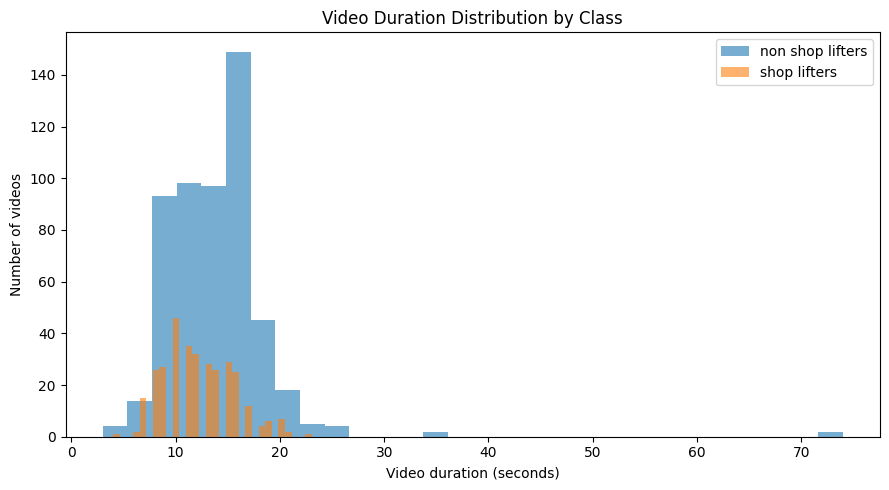

In [4]:
# Extract the dataset and inspect video metadata
import os
import zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

zip_path = "/content/Shop_DataSet.zip"
extract_dir = "/content/shop_dataset"
dataset_root = os.path.join(extract_dir, "Shop DataSet")

if not os.path.isdir(dataset_root):
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_dir)

print("Dataset extracted:", os.path.isdir(dataset_root))

video_rows = []
failed_videos = []

class_folders = {
    "non shop lifters": 0,
    "shop lifters": 1
}

for class_name, label in class_folders.items():
    class_dir = os.path.join(dataset_root, class_name)

    for filename in os.listdir(class_dir):
        if not filename.lower().endswith(".mp4"):
            continue

        video_path = os.path.join(class_dir, filename)
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            failed_videos.append(video_path)
            cap.release()
            continue

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        cap.release()

        duration = frame_count / fps if fps > 0 else np.nan

        video_rows.append({
            "filename": filename,
            "class_name": class_name,
            "label": label,
            "frame_count": frame_count,
            "fps": fps,
            "width": width,
            "height": height,
            "duration_sec": duration
        })

df_videos = pd.DataFrame(video_rows)

print("\nSuccessfully inspected:", len(df_videos))
print("Unreadable videos:", len(failed_videos))

print("\nDuration summary (seconds):")
print(
    df_videos.groupby("class_name")["duration_sec"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("\nMost common resolutions:")
print(
    df_videos.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nFrame-rate summary:")
print(df_videos["fps"].describe().round(2))

print("\nDuration percentiles (seconds):")
print(df_videos["duration_sec"].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 1]
).round(2))

plt.figure(figsize=(9, 5))
for class_name in class_folders:
    durations = df_videos.loc[
        df_videos["class_name"] == class_name, "duration_sec"
    ].dropna()
    plt.hist(durations, bins=30, alpha=0.6, label=class_name)

plt.xlabel("Video duration (seconds)")
plt.ylabel("Number of videos")
plt.title("Video Duration Distribution by Class")
plt.legend()
plt.tight_layout()
plt.show()


Shortest: shop_lifter_n_215_1.mp4
Duration: 3.00 seconds
Original frames: 75
Sampled frames: 32
Tensor shape: (32, 3, 104, 128)
First sampled index: 0
Last sampled index: 74


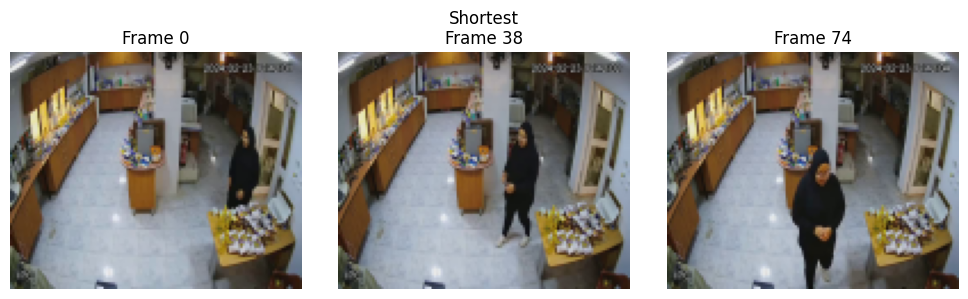


Median-duration: shop_lifter_n_19_1.mp4
Duration: 13.00 seconds
Original frames: 325
Sampled frames: 32
Tensor shape: (32, 3, 104, 128)
First sampled index: 0
Last sampled index: 324


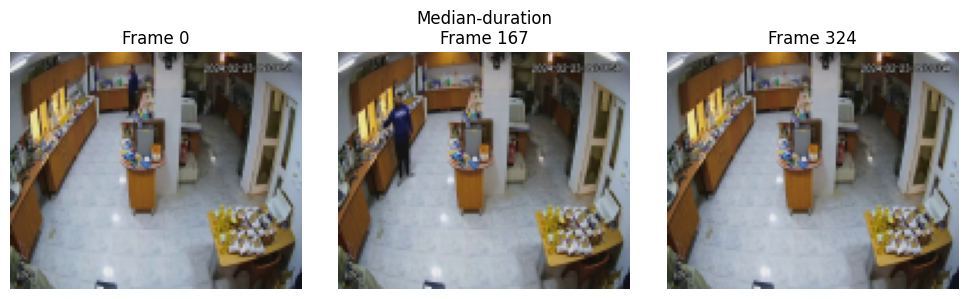


Longest: shop_lifter_n_13.mp4
Duration: 74.00 seconds
Original frames: 1850
Sampled frames: 32
Tensor shape: (32, 3, 104, 128)
First sampled index: 0
Last sampled index: 1849


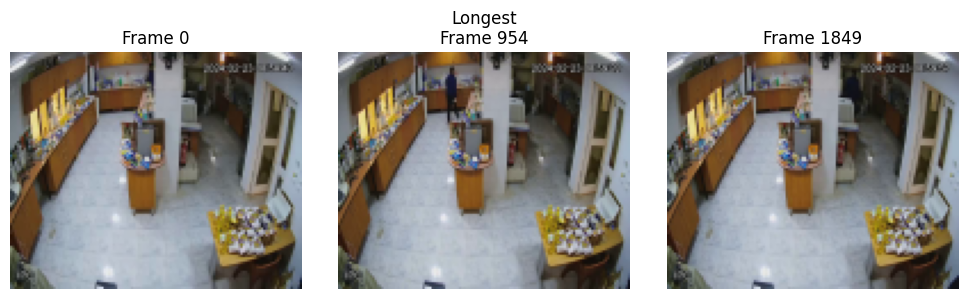

In [5]:
# Sample a fixed number of frames uniformly across each video
import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

NUM_FRAMES = 32
FRAME_WIDTH = 128
FRAME_HEIGHT = 104


def sample_video_frames(video_path, num_frames=NUM_FRAMES):
    """Return a video tensor with shape (T, C, H, W)."""

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError(f"Invalid frame count: {video_path}")

    # Select evenly spaced indices across the entire video.
    frame_indices = np.linspace(
        0, total_frames - 1, num_frames
    ).round().astype(np.int64)

    sampled_frames = []
    last_valid_frame = None

    for frame_index in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        success, frame = cap.read()

        if not success:
            if last_valid_frame is None:
                cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                success, frame = cap.read()

            if not success:
                cap.release()
                raise ValueError(
                    f"Could not decode sampled frame {frame_index} "
                    f"from {video_path}"
                )

            if frame is None:
                frame = last_valid_frame.copy()

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(
            frame,
            (FRAME_WIDTH, FRAME_HEIGHT),
            interpolation=cv2.INTER_AREA
        )

        last_valid_frame = frame.copy()
        sampled_frames.append(frame)

    cap.release()

    # Convert THWC uint8 frames into a TCHW tensor.
    frame_array = np.stack(sampled_frames, axis=0)
    video_tensor = torch.from_numpy(frame_array).permute(
        0, 3, 1, 2
    ).contiguous()

    return video_tensor, frame_indices, total_frames


# Test the sampler on short, typical, and long videos.
median_duration = df_videos["duration_sec"].median()

test_rows = [
    ("Shortest", df_videos.loc[df_videos["duration_sec"].idxmin()]),
    (
        "Median-duration",
        df_videos.loc[
            (df_videos["duration_sec"] - median_duration).abs().idxmin()
        ]
    ),
    ("Longest", df_videos.loc[df_videos["duration_sec"].idxmax()])
]

for description, row in test_rows:
    video_path = os.path.join(
        dataset_root, row["class_name"], row["filename"]
    )

    video_tensor, frame_indices, total_frames = sample_video_frames(
        video_path
    )

    print(f"\n{description}: {row['filename']}")
    print(f"Duration: {row['duration_sec']:.2f} seconds")
    print(f"Original frames: {total_frames}")
    print(f"Sampled frames: {len(frame_indices)}")
    print(f"Tensor shape: {tuple(video_tensor.shape)}")
    print(f"First sampled index: {frame_indices[0]}")
    print(f"Last sampled index: {frame_indices[-1]}")

    # Display sampled frames from the beginning, middle, and end.
    selected_positions = [0, NUM_FRAMES // 2, NUM_FRAMES - 1]

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    for ax, position in zip(axes, selected_positions):
        frame = video_tensor[position].permute(1, 2, 0).numpy()
        ax.imshow(frame)
        ax.set_title(f"Frame {frame_indices[position]}")
        ax.axis("off")

    fig.suptitle(description)
    plt.tight_layout()
    plt.show()

In [6]:
# Split videos into training, validation, and test sets
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_videos,
    test_size=0.30,
    random_state=42,
    stratify=df_videos["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Number of videos:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass distribution:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{split_name}:")
    print(split_df["class_name"].value_counts())
    print("Class proportions:")
    print(split_df["label"].value_counts(normalize=True).round(3))

Number of videos:
Train: 598
Validation: 128
Test: 129

Class distribution:

Train:
class_name
non shop lifters    371
shop lifters        227
Name: count, dtype: int64
Class proportions:
label
0    0.62
1    0.38
Name: proportion, dtype: float64

Validation:
class_name
non shop lifters    80
shop lifters        48
Name: count, dtype: int64
Class proportions:
label
0    0.625
1    0.375
Name: proportion, dtype: float64

Test:
class_name
non shop lifters    80
shop lifters        49
Name: count, dtype: int64
Class proportions:
label
0    0.62
1    0.38
Name: proportion, dtype: float64


In [7]:
# Build a video dataset with consistent clip-level augmentation
import random
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


NUM_FRAMES = 32
BATCH_SIZE = 4


def augment_clip(frames):
    """Apply shared spatial and color transformations to a video clip."""
    # frames has shape (T, C, H, W), with values in [0, 1].
    _, _, height, width = frames.shape

    # Apply the same horizontal and vertical flips to every frame.
    if random.random() < 0.5:
        frames = torch.flip(frames, dims=[-1])

    if random.random() < 0.5:
        frames = torch.flip(frames, dims=[-2])

    # Choose one crop for the entire clip, then resize to the original shape.
    scale = random.uniform(0.90, 1.0)
    crop_h = max(1, round(height * scale))
    crop_w = max(1, round(width * scale))

    top = random.randint(0, height - crop_h)
    left = random.randint(0, width - crop_w)

    frames = frames[
        :, :, top:top + crop_h, left:left + crop_w
    ]

    frames = F.interpolate(
        frames,
        size=(height, width),
        mode="bilinear",
        align_corners=False
    )

    # Use the same color-jitter factors throughout the clip.
    brightness = random.uniform(0.9, 1.1)
    contrast = random.uniform(0.9, 1.1)
    saturation = random.uniform(0.9, 1.1)

    frames = frames * brightness

    # Adjust contrast using each frame's own mean.
    frame_means = frames.mean(
        dim=(1, 2, 3), keepdim=True
    )
    frames = (frames - frame_means) * contrast + frame_means

    # Adjust saturation consistently across all frames.
    gray = (
        0.2989 * frames[:, 0:1]
        + 0.5870 * frames[:, 1:2]
        + 0.1140 * frames[:, 2:3]
    )
    frames = gray + saturation * (frames - gray)

    return frames.clamp(0.0, 1.0)


class ShopliftingVideoDataset(Dataset):
    """Load a fixed number of frames and a class label per video."""

    def __init__(
        self,
        dataframe,
        dataset_root,
        num_frames=NUM_FRAMES,
        augment=False
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_root = dataset_root
        self.num_frames = num_frames
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        video_path = os.path.join(
            self.dataset_root,
            row["class_name"],
            row["filename"]
        )

        # Decode uniformly sampled frames using our tested sampler.
        frames, _, _ = sample_video_frames(
            video_path,
            num_frames=self.num_frames
        )

        # Convert uint8 RGB frames to float tensors in [0, 1].
        frames = frames.float() / 255.0

        # Augmentation is used for training videos only.
        if self.augment:
            frames = augment_clip(frames)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return frames, label


# Build independent datasets for each split.
train_dataset = ShopliftingVideoDataset(
    train_df, dataset_root, augment=True
)

val_dataset = ShopliftingVideoDataset(
    val_df, dataset_root, augment=False
)

test_dataset = ShopliftingVideoDataset(
    test_df, dataset_root, augment=False
)

# Keep loading simple while we verify the pipeline.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch from each split.
for split_name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    videos, labels = next(iter(loader))

    print(f"\n{split_name}:")
    print("Video batch shape:", tuple(videos.shape))
    print("Labels shape:", tuple(labels.shape))
    print("Labels in batch:", labels.tolist())
    print("Tensor dtype:", videos.dtype)
    print("Value range:", (
        round(videos.min().item(), 3),
        round(videos.max().item(), 3)
    ))


Train:
Video batch shape: (4, 32, 3, 104, 128)
Labels shape: (4,)
Labels in batch: [1, 1, 1, 1]
Tensor dtype: torch.float32
Value range: (0.011, 0.935)

Validation:
Video batch shape: (4, 32, 3, 104, 128)
Labels shape: (4,)
Labels in batch: [0, 1, 0, 1]
Tensor dtype: torch.float32
Value range: (0.016, 0.961)

Test:
Video batch shape: (4, 32, 3, 104, 128)
Labels shape: (4,)
Labels in batch: [1, 1, 0, 1]
Tensor dtype: torch.float32
Value range: (0.012, 0.976)


In [8]:
# Build a 3D CNN for video-level shoplifting classification
import torch
import torch.nn as nn


class Shoplifting3DCNN(nn.Module):
    """Classify a video using spatiotemporal 3D convolutions."""

    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            # Learn low-level spatial and temporal features.
            nn.Conv3d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1, 2, 2)),

            nn.Conv3d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2),

            nn.Conv3d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2),

            nn.Conv3d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2),
        )

        # Aggregate spatial and temporal features into one vector.
        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, videos):
        # Convert (B, T, C, H, W) to (B, C, T, H, W).
        videos = videos.permute(0, 2, 1, 3, 4).contiguous()

        features = self.features(videos)
        features = self.global_pool(features)

        return self.classifier(features)


# Use the available GPU when possible.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Shoplifting3DCNN().to(device)

# Test one batch without performing training.
sample_videos, sample_labels = next(iter(train_loader))

model.eval()
with torch.no_grad():
    sample_logits = model(sample_videos.to(device))

print("Device:", device)
print("Input batch shape:", tuple(sample_videos.shape))
print("Model output shape:", tuple(sample_logits.shape))
print("Labels shape:", tuple(sample_labels.shape))
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cuda
Input batch shape: (4, 32, 3, 104, 128)
Model output shape: (4, 2)
Labels shape: (4,)
Trainable parameters: 292338


In [9]:
# Cache the sampled frames from all videos for faster training
import os
import numpy as np

cache_path = "/content/shop_video_frames.npy"
num_videos = len(df_videos)

if os.path.isfile(cache_path):
    frame_cache = np.load(cache_path, mmap_mode="r")
    print("Existing frame cache loaded.")

else:
    cache_shape = (
        num_videos,
        NUM_FRAMES,
        FRAME_HEIGHT,
        FRAME_WIDTH,
        3
    )

    frame_cache = np.lib.format.open_memmap(
        cache_path,
        mode="w+",
        dtype=np.uint8,
        shape=cache_shape
    )

    for index, row in df_videos.reset_index(drop=True).iterrows():
        video_path = os.path.join(
            dataset_root,
            row["class_name"],
            row["filename"]
        )

        clip, _, _ = sample_video_frames(
            video_path,
            num_frames=NUM_FRAMES
        )

        # Store frames as T, H, W, C in uint8 format.
        frame_cache[index] = (
            clip.permute(0, 2, 3, 1).numpy()
        )

        if (index + 1) % 50 == 0 or index + 1 == num_videos:
            print(f"Cached {index + 1}/{num_videos} videos")

    frame_cache.flush()
    print("Frame cache created successfully.")

print("Cache shape:", frame_cache.shape)
print("Cache dtype:", frame_cache.dtype)
print(f"Cache size: {os.path.getsize(cache_path) / (1024**3):.2f} GB")

Cached 50/855 videos
Cached 100/855 videos
Cached 150/855 videos
Cached 200/855 videos
Cached 250/855 videos
Cached 300/855 videos
Cached 350/855 videos
Cached 400/855 videos
Cached 450/855 videos
Cached 500/855 videos
Cached 550/855 videos
Cached 600/855 videos
Cached 650/855 videos
Cached 700/855 videos
Cached 750/855 videos
Cached 800/855 videos
Cached 850/855 videos
Cached 855/855 videos
Frame cache created successfully.
Cache shape: (855, 32, 104, 128, 3)
Cache dtype: uint8
Cache size: 1.02 GB


In [10]:
# Use cached frames instead of decoding MP4 files repeatedly
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Open the cache without loading the entire file into RAM.
frame_cache = np.load(cache_path, mmap_mode="r")

# Map each video to its position in the cache.
cache_index = {
    (row["class_name"], row["filename"]): index
    for index, row in df_videos.reset_index(drop=True).iterrows()
}


class CachedShopliftingVideoDataset(Dataset):
    """Load cached video frames and optionally augment the clip."""

    def __init__(self, dataframe, augment=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        key = (row["class_name"], row["filename"])

        # Copy the cached frames before converting them to a tensor.
        frames_array = np.array(
            frame_cache[cache_index[key]],
            copy=True
        )

        # Convert (T, H, W, C) to (T, C, H, W).
        frames = torch.from_numpy(frames_array)
        frames = frames.permute(0, 3, 1, 2).float() / 255.0

        if self.augment:
            frames = augment_clip(frames)

        label = torch.tensor(int(row["label"]), dtype=torch.long)

        return frames, label


# Rebuild datasets using cached frames.
train_dataset = CachedShopliftingVideoDataset(train_df, augment=True)
val_dataset = CachedShopliftingVideoDataset(val_df, augment=False)
test_dataset = CachedShopliftingVideoDataset(test_df, augment=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one cached batch.
videos, labels = next(iter(train_loader))

print("Video batch shape:", tuple(videos.shape))
print("Labels shape:", tuple(labels.shape))
print("Tensor dtype:", videos.dtype)
print("Value range:", videos.min().item(), videos.max().item())
print("Cache-based dataset ready.")

Video batch shape: (4, 32, 3, 104, 128)
Labels shape: (4,)
Tensor dtype: torch.float32
Value range: 0.023870505392551422 0.9787579774856567
Cache-based dataset ready.


In [11]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
# Train the 3D CNN and save the best checkpoint to Google Drive
import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Training configuration
num_epochs = 15
patience = 4
learning_rate = 1e-3

save_dir = "/content/drive/MyDrive/Shoplifting_Detection"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(
    save_dir, "best_shoplifting_3dcnn.pth"
)

history_path = os.path.join(
    save_dir, "training_history.csv"
)

# Save the exact video split for future reproducibility.
split_frames = []

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    part = split_df.copy()
    part["split"] = split_name
    split_frames.append(part)

pd.concat(split_frames, ignore_index=True).to_csv(
    os.path.join(save_dir, "video_splits.csv"),
    index=False
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

def calculate_binary_metrics(predictions, targets):
    """Calculate metrics for the shoplifting class (label 1)."""
    tp = ((predictions == 1) & (targets == 1)).sum().item()
    fp = ((predictions == 1) & (targets == 0)).sum().item()
    fn = ((predictions == 0) & (targets == 1)).sum().item()

    accuracy = (predictions == targets).float().mean().item()
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    return accuracy, precision, recall, f1


best_val_f1 = -1.0
best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

print("Training device:", device)
print("Maximum epochs:", num_epochs)
print("Checkpoint:", checkpoint_path)

for epoch in range(num_epochs):
    # Training phase
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for videos, labels in train_loader:
        videos = videos.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(videos)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_count += labels.size(0)

    train_loss = train_loss_sum / max(train_count, 1)

    # Validation phase
    model.eval()
    val_loss_sum = 0.0
    val_count = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for videos, labels in val_loader:
            videos = videos.to(device)
            labels = labels.to(device)

            logits = model(videos)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_count += labels.size(0)

            predictions = logits.argmax(dim=1)

            all_predictions.append(predictions.cpu())
            all_targets.append(labels.cpu())

    val_loss = val_loss_sum / max(val_count, 1)

    all_predictions = torch.cat(all_predictions)
    all_targets = torch.cat(all_targets)

    val_accuracy, val_precision, val_recall, val_f1 = (
        calculate_binary_metrics(all_predictions, all_targets)
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "val_f1": val_f1,
        "learning_rate": current_lr,
    }

    history.append(row)

    # Save the checkpoint whenever validation F1 improves.
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_loss = val_loss
        epochs_without_improvement = 0

        checkpoint = {
            "model_state_dict": {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            },
            "architecture": "Shoplifting3DCNN",
            "num_classes": 2,
            "num_frames": NUM_FRAMES,
            "frame_height": FRAME_HEIGHT,
            "frame_width": FRAME_WIDTH,
            "class_mapping": {
                "0": "Normal shopping",
                "1": "Shoplifting",
            },
            "best_epoch": epoch + 1,
            "validation_metrics": {
                "loss": val_loss,
                "accuracy": val_accuracy,
                "precision": val_precision,
                "recall": val_recall,
                "f1": val_f1,
            },
        }

        torch.save(checkpoint, checkpoint_path)
        saved_message = " | Best checkpoint saved"
    else:
        epochs_without_improvement += 1
        saved_message = ""

    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"LR: {current_lr:.1e}"
        f"{saved_message}"
    )

    if epochs_without_improvement >= patience:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

# Restore the best validation checkpoint.
best_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("\nTraining finished.")
print("Best epoch:", best_checkpoint["best_epoch"])
print(f"Best validation F1: {best_val_f1:.4f}")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint saved:", checkpoint_path)
print("Training history saved:", history_path)

Training device: cuda
Maximum epochs: 15
Checkpoint: /content/drive/MyDrive/Shoplifting_Detection/best_shoplifting_3dcnn.pth
Epoch 01/15 | Train Loss: 0.6913 | Val Loss: 0.6519 | Val Accuracy: 0.6250 | Val Precision: 0.0000 | Val Recall: 0.0000 | Val F1: 0.0000 | LR: 1.0e-03 | Best checkpoint saved
Epoch 02/15 | Train Loss: 0.6621 | Val Loss: 0.6390 | Val Accuracy: 0.6250 | Val Precision: 0.0000 | Val Recall: 0.0000 | Val F1: 0.0000 | LR: 1.0e-03
Epoch 03/15 | Train Loss: 0.6590 | Val Loss: 0.6246 | Val Accuracy: 0.6328 | Val Precision: 1.0000 | Val Recall: 0.0208 | Val F1: 0.0408 | LR: 1.0e-03 | Best checkpoint saved
Epoch 04/15 | Train Loss: 0.6407 | Val Loss: 0.5895 | Val Accuracy: 0.6484 | Val Precision: 1.0000 | Val Recall: 0.0625 | Val F1: 0.1176 | LR: 1.0e-03 | Best checkpoint saved
Epoch 05/15 | Train Loss: 0.6519 | Val Loss: 1.1592 | Val Accuracy: 0.6250 | Val Precision: 0.0000 | Val Recall: 0.0000 | Val F1: 0.0000 | LR: 1.0e-03
Epoch 06/15 | Train Loss: 0.6076 | Val Loss: 0.9

In [13]:
# Evaluate the best saved checkpoint on the held-out test set
import torch
import torch.nn as nn

checkpoint_path = (
    "/content/drive/MyDrive/Shoplifting_Detection/"
    "best_shoplifting_3dcnn.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

criterion = nn.CrossEntropyLoss()

all_predictions = []
all_targets = []
test_loss_sum = 0.0
num_samples = 0

with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.to(device)
        labels = labels.to(device)

        logits = model(videos)
        loss = criterion(logits, labels)

        predictions = logits.argmax(dim=1)

        test_loss_sum += loss.item() * labels.size(0)
        num_samples += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_targets.extend(labels.cpu().tolist())

predictions = torch.tensor(all_predictions)
targets = torch.tensor(all_targets)

tp = int(((predictions == 1) & (targets == 1)).sum())
tn = int(((predictions == 0) & (targets == 0)).sum())
fp = int(((predictions == 1) & (targets == 0)).sum())
fn = int(((predictions == 0) & (targets == 1)).sum())

test_accuracy = (tp + tn) / max(num_samples, 1)
test_precision = tp / (tp + fp) if tp + fp else 0.0
test_recall = tp / (tp + fn) if tp + fn else 0.0
test_f1 = (
    2 * test_precision * test_recall
    / (test_precision + test_recall)
    if test_precision + test_recall else 0.0
)

print("Best checkpoint epoch:", checkpoint["best_epoch"])
print(f"Test Loss: {test_loss_sum / num_samples:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1-score: {test_f1:.4f}")

print("\nConfusion Matrix:")
print("                 Predicted Normal  Predicted Shoplifting")
print(f"Actual Normal          {tn:3d}                  {fp:3d}")
print(f"Actual Shoplifting     {fn:3d}                  {tp:3d}")

print("\nTotal test videos:", num_samples)

Best checkpoint epoch: 9
Test Loss: 0.5094
Test Accuracy: 0.7907
Test Precision: 0.6833
Test Recall: 0.8367
Test F1-score: 0.7523

Confusion Matrix:
                 Predicted Normal  Predicted Shoplifting
Actual Normal           61                   19
Actual Shoplifting       8                   41

Total test videos: 129


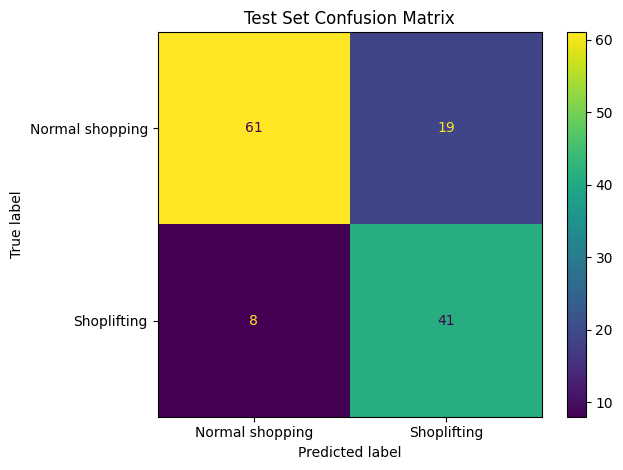

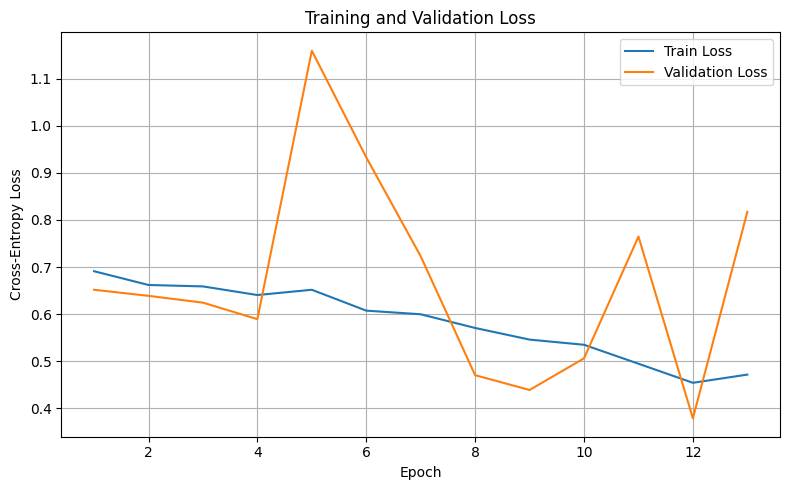

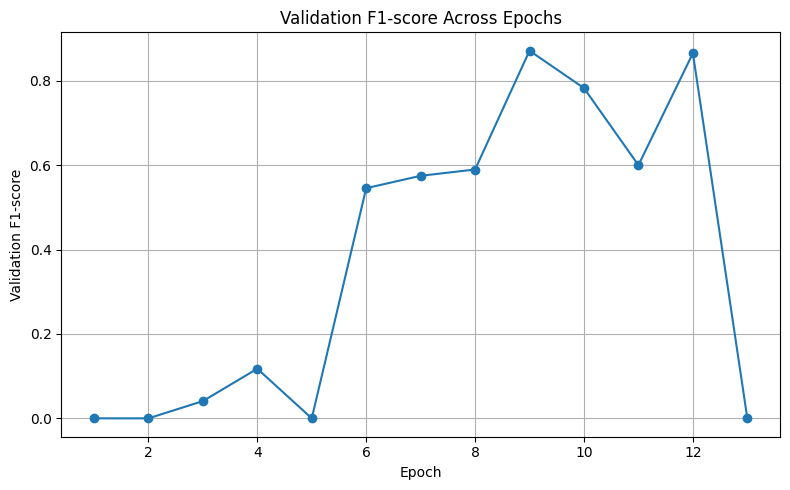

In [15]:
# Visualize the confusion matrix and training history
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

# Build the confusion matrix from the saved test evaluation.
cm = np.array([
    [tn, fp],
    [fn, tp]
])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal shopping", "Shoplifting"]
)

display.plot(values_format="d")
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# Plot training and validation loss.
history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot validation F1 across epochs.
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["val_f1"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation F1-score")
plt.title("Validation F1-score Across Epochs")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# Tune the decision threshold using validation data only
import numpy as np
import pandas as pd
import torch

checkpoint_path = (
    "/content/drive/MyDrive/Shoplifting_Detection/"
    "best_shoplifting_3dcnn.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

val_probabilities = []
val_targets = []

with torch.no_grad():
    for videos, labels in val_loader:
        videos = videos.to(device)

        logits = model(videos)
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        val_probabilities.extend(probabilities.cpu().numpy())
        val_targets.extend(labels.numpy())

val_probabilities = np.asarray(val_probabilities)
val_targets = np.asarray(val_targets)

results = []

for threshold in np.arange(0.20, 0.801, 0.025):
    predictions = (val_probabilities >= threshold).astype(int)

    tp = np.sum((predictions == 1) & (val_targets == 1))
    fp = np.sum((predictions == 1) & (val_targets == 0))
    fn = np.sum((predictions == 0) & (val_targets == 1))
    tn = np.sum((predictions == 0) & (val_targets == 0))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    accuracy = (tp + tn) / len(val_targets)

    results.append({
        "threshold": round(float(threshold), 3),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

results_df = pd.DataFrame(results)

best_index = results_df["f1"].idxmax()
best_result = results_df.loc[best_index]

print("Validation results at threshold 0.50:")
print(
    results_df.iloc[
        (results_df["threshold"] - 0.50).abs().argmin()
    ].to_string()
)

print("\nBest threshold based on validation F1:")
print(best_result.to_string())

print("\nTop 5 thresholds by validation F1:")
print(
    results_df.sort_values("f1", ascending=False)
    .head(5)
    .round(4)
    .to_string(index=False)
)

Validation results at threshold 0.50:
threshold    0.500000
accuracy     0.898438
precision    0.830189
recall       0.916667
f1           0.871287

Best threshold based on validation F1:
threshold    0.525000
accuracy     0.906250
precision    0.846154
recall       0.916667
f1           0.880000

Top 5 thresholds by validation F1:
 threshold  accuracy  precision  recall     f1
     0.525    0.9062     0.8462  0.9167 0.8800
     0.500    0.8984     0.8302  0.9167 0.8713
     0.550    0.8906     0.8400  0.8750 0.8571
     0.575    0.8906     0.8400  0.8750 0.8571
     0.450    0.8750     0.7759  0.9375 0.8491


In [17]:
# Evaluate the validation-selected threshold on the test set
import torch
import numpy as np

checkpoint_path = (
    "/content/drive/MyDrive/Shoplifting_Detection/"
    "best_shoplifting_3dcnn.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

selected_threshold = 0.525

all_probabilities = []
all_targets = []

with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.to(device)

        logits = model(videos)
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )
        all_targets.extend(labels.numpy())

probabilities = np.asarray(all_probabilities)
targets = np.asarray(all_targets)

predictions = (probabilities >= selected_threshold).astype(int)

tp = int(np.sum((predictions == 1) & (targets == 1)))
tn = int(np.sum((predictions == 0) & (targets == 0)))
fp = int(np.sum((predictions == 1) & (targets == 0)))
fn = int(np.sum((predictions == 0) & (targets == 1)))

accuracy = (tp + tn) / len(targets)
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print("Checkpoint epoch:", checkpoint["best_epoch"])
print("Decision threshold:", selected_threshold)
print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print("                 Predicted Normal  Predicted Shoplifting")
print(f"Actual Normal          {tn:3d}                  {fp:3d}")
print(f"Actual Shoplifting     {fn:3d}                  {tp:3d}")

Checkpoint epoch: 9
Decision threshold: 0.525
Test Accuracy:  0.7984
Test Precision: 0.7018
Test Recall:    0.8163
Test F1-score:  0.7547

Confusion Matrix:
                 Predicted Normal  Predicted Shoplifting
Actual Normal           63                   17
Actual Shoplifting       9                   40


In [18]:
# Save the final model checkpoint and evaluation report
import os
import json
import torch

save_dir = "/content/drive/MyDrive/Shoplifting_Detection"

checkpoint_path = os.path.join(
    save_dir, "best_shoplifting_3dcnn.pth"
)

final_checkpoint_path = os.path.join(
    save_dir, "final_shoplifting_3dcnn.pth"
)

report_path = os.path.join(
    save_dir, "final_evaluation_report.json"
)

# Load the best checkpoint selected using validation F1.
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Record the final decision threshold selected on validation data.
checkpoint["decision_threshold"] = 0.525

checkpoint["validation_metrics_at_selected_threshold"] = {
    "accuracy": 0.90625,
    "precision": 0.846154,
    "recall": 0.916667,
    "f1": 0.880000
}

checkpoint["test_metrics_at_selected_threshold"] = {
    "accuracy": 0.7984,
    "precision": 0.7018,
    "recall": 0.8163,
    "f1": 0.7547
}

torch.save(checkpoint, final_checkpoint_path)

# Document the evaluation results and confusion matrix.
report = {
    "architecture": "Shoplifting3DCNN",
    "best_epoch": checkpoint["best_epoch"],
    "num_frames": 32,
    "input_shape_per_video": [32, 3, 104, 128],
    "class_mapping": {
        "0": "Normal shopping",
        "1": "Shoplifting"
    },
    "decision_threshold": 0.525,
    "validation_metrics": {
        "accuracy": 0.90625,
        "precision": 0.846154,
        "recall": 0.916667,
        "f1": 0.880000
    },
    "test_metrics": {
        "accuracy": 0.7984,
        "precision": 0.7018,
        "recall": 0.8163,
        "f1": 0.7547
    },
    "test_confusion_matrix": {
        "true_negative": 63,
        "false_positive": 17,
        "false_negative": 9,
        "true_positive": 40
    },
    "test_samples": 129
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("Final checkpoint saved:", final_checkpoint_path)
print("Evaluation report saved:", report_path)
print("Best epoch:", checkpoint["best_epoch"])
print("Decision threshold:", checkpoint["decision_threshold"])

Final checkpoint saved: /content/drive/MyDrive/Shoplifting_Detection/final_shoplifting_3dcnn.pth
Evaluation report saved: /content/drive/MyDrive/Shoplifting_Detection/final_evaluation_report.json
Best epoch: 9
Decision threshold: 0.525


In [19]:
# Install ONNX validation and inference tools
!pip -q install onnx onnxruntime

import onnx
import onnxruntime as ort

print("ONNX version:", onnx.__version__)
print("ONNX Runtime version:", ort.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 51.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 81.6 MB/s eta 0:00:00
ONNX version: 1.23.2
ONNX Runtime version: 1.31.0


In [20]:
# Export the best 3D CNN checkpoint to ONNX and verify its outputs
import os
import numpy as np
import torch
import onnx
import onnxruntime as ort

save_dir = "/content/drive/MyDrive/Shoplifting_Detection"

checkpoint_path = os.path.join(
    save_dir, "final_shoplifting_3dcnn.pth"
)
onnx_path = os.path.join(
    save_dir, "shoplifting_3dcnn.onnx"
)

# Recreate the model and load the saved checkpoint on CPU.
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

export_model = Shoplifting3DCNN().cpu()
export_model.load_state_dict(checkpoint["model_state_dict"])
export_model.eval()

# Use one test video as the example input for export.
test_videos, test_labels = next(iter(test_loader))
example_input = test_videos[:1].cpu().contiguous()

# Export with a dynamic batch dimension.
torch.onnx.export(
    export_model,
    (example_input,),
    onnx_path,
    input_names=["video"],
    output_names=["logits"],
    dynamic_axes={
        "video": {0: "batch_size"},
        "logits": {0: "batch_size"}
    },
    opset_version=17,
    do_constant_folding=True,
    dynamo=False
)

# Validate the exported ONNX graph.
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

# Load the ONNX model using CPU inference.
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# Compare PyTorch and ONNX outputs on two test videos.
comparison_input = test_videos[:2].cpu().contiguous()

with torch.no_grad():
    pytorch_logits = export_model(comparison_input).numpy()

onnx_logits = session.run(
    ["logits"],
    {"video": comparison_input.numpy().astype(np.float32)}
)[0]

max_abs_error = float(
    np.max(np.abs(pytorch_logits - onnx_logits))
)

outputs_close = np.allclose(
    pytorch_logits,
    onnx_logits,
    atol=1e-4,
    rtol=1e-3
)

pytorch_predictions = pytorch_logits.argmax(axis=1)
onnx_predictions = onnx_logits.argmax(axis=1)

print("ONNX export successful.")
print("ONNX file:", onnx_path)
print(f"ONNX file size: {os.path.getsize(onnx_path) / (1024**2):.2f} MB")
print("Input shape:", tuple(comparison_input.shape))
print("PyTorch output shape:", pytorch_logits.shape)
print("ONNX output shape:", onnx_logits.shape)
print(f"Maximum absolute logit difference: {max_abs_error:.8f}")
print("Outputs numerically close:", outputs_close)
print("PyTorch predictions:", pytorch_predictions.tolist())
print("ONNX predictions:", onnx_predictions.tolist())

/tmp/ipykernel_647/2570283698.py:33: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX export successful.
ONNX file: /content/drive/MyDrive/Shoplifting_Detection/shoplifting_3dcnn.onnx
ONNX file size: 1.12 MB
Input shape: (2, 32, 3, 104, 128)
PyTorch output shape: (2, 2)
ONNX output shape: (2, 2)
Maximum absolute logit difference: 0.00000048
Outputs numerically close: True
PyTorch predictions: [1, 1]
ONNX predictions: [1, 1]


In [21]:
# Evaluate the exported ONNX model on the full test set
import numpy as np
import onnxruntime as ort

onnx_path = (
    "/content/drive/MyDrive/Shoplifting_Detection/"
    "shoplifting_3dcnn.onnx"
)

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

threshold = 0.525
all_predictions_onnx = []
all_targets_onnx = []

for videos, labels in test_loader:
    videos_np = videos.numpy().astype(np.float32)

    logits = session.run(
        ["logits"],
        {"video": videos_np}
    )[0]

    # Convert logits to shoplifting probabilities.
    shifted_logits = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(shifted_logits)
    probabilities = exp_logits / exp_logits.sum(axis=1, keepdims=True)

    predictions = (probabilities[:, 1] >= threshold).astype(int)

    all_predictions_onnx.extend(predictions.tolist())
    all_targets_onnx.extend(labels.numpy().tolist())

predictions = np.asarray(all_predictions_onnx)
targets = np.asarray(all_targets_onnx)

tp = int(np.sum((predictions == 1) & (targets == 1)))
tn = int(np.sum((predictions == 0) & (targets == 0)))
fp = int(np.sum((predictions == 1) & (targets == 0)))
fn = int(np.sum((predictions == 0) & (targets == 1)))

accuracy = (tp + tn) / len(targets)
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print("Runtime: ONNX Runtime CPU")
print("Threshold:", threshold)
print("Test videos:", len(targets))
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print("                 Predicted Normal  Predicted Shoplifting")
print(f"Actual Normal          {tn:3d}                  {fp:3d}")
print(f"Actual Shoplifting     {fn:3d}                  {tp:3d}")

Runtime: ONNX Runtime CPU
Threshold: 0.525
Test videos: 129
Accuracy:  0.7984
Precision: 0.7018
Recall:    0.8163
F1-score:  0.7547

Confusion Matrix:
                 Predicted Normal  Predicted Shoplifting
Actual Normal           63                   17
Actual Shoplifting       9                   40


In [22]:
%%writefile /content/drive/MyDrive/Shoplifting_Detection/inference_onnx.py
from pathlib import Path
import argparse

import cv2
import numpy as np
import onnxruntime as ort


BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "shoplifting_3dcnn.onnx"

NUM_FRAMES = 32
FRAME_WIDTH = 128
FRAME_HEIGHT = 104
THRESHOLD = 0.525

CLASS_NAMES = {
    0: "Normal shopping",
    1: "Shoplifting"
}


def sample_video(video_path):
    """Sample 32 uniformly spaced RGB frames from an MP4 video."""

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError("The video contains no readable frames.")

    indices = np.linspace(
        0, total_frames - 1, NUM_FRAMES
    ).round().astype(np.int64)

    frames = []

    for index in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(f"Could not read frame {index}.")

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(
            frame,
            (FRAME_WIDTH, FRAME_HEIGHT),
            interpolation=cv2.INTER_AREA
        )
        frames.append(frame)

    cap.release()

    # Convert (T, H, W, C) into (1, T, C, H, W).
    video = np.stack(frames).astype(np.float32) / 255.0
    video = np.transpose(video, (0, 3, 1, 2))
    video = np.expand_dims(video, axis=0)

    return np.ascontiguousarray(video, dtype=np.float32)


def predict_video(video_path):
    """Return the predicted class and shoplifting probability."""

    if not MODEL_PATH.is_file():
        raise FileNotFoundError(
            f"ONNX model not found: {MODEL_PATH}"
        )

    session = ort.InferenceSession(
        str(MODEL_PATH),
        providers=["CPUExecutionProvider"]
    )

    video = sample_video(video_path)

    logits = session.run(
        ["logits"],
        {"video": video}
    )[0]

    # Convert logits to probabilities with a stable softmax.
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    probabilities = exp_values / np.sum(
        exp_values, axis=1, keepdims=True
    )

    shoplifting_probability = float(probabilities[0, 1])
    predicted_class = int(
        shoplifting_probability >= THRESHOLD
    )

    return {
        "predicted_class": CLASS_NAMES[predicted_class],
        "shoplifting_probability": shoplifting_probability,
        "threshold": THRESHOLD,
        "sampled_frames": NUM_FRAMES,
    }


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Classify a shopping video using ONNX Runtime."
    )
    parser.add_argument(
        "--video",
        required=True,
        help="Path to an MP4 video."
    )
    args = parser.parse_args()

    result = predict_video(args.video)

    print("Predicted class:", result["predicted_class"])
    print(
        "Shoplifting probability:",
        f"{result['shoplifting_probability']:.4f}"
    )
    print("Decision threshold:", result["threshold"])
    print("Sampled frames:", result["sampled_frames"])

Writing /content/drive/MyDrive/Shoplifting_Detection/inference_onnx.py


In [23]:
# Run the standalone ONNX inference script on a real video
!python "/content/drive/MyDrive/Shoplifting_Detection/inference_onnx.py" \
    --video "/content/shop_dataset/Shop DataSet/non shop lifters/shop_lifter_n_0.mp4"

Predicted class: Normal shopping
Shoplifting probability: 0.4361
Decision threshold: 0.525
Sampled frames: 32


In [24]:
# Test inference on a video from the shoplifting class
!python "/content/drive/MyDrive/Shoplifting_Detection/inference_onnx.py" \
    --video "/content/shop_dataset/Shop DataSet/shop lifters/shop_lifter_0.mp4"

Predicted class: Shoplifting
Shoplifting probability: 0.6273
Decision threshold: 0.525
Sampled frames: 32


In [25]:
# List the saved project files and their sizes
!ls -lh "/content/drive/MyDrive/Shoplifting_Detection"

total 3.5M
-rw------- 1 root root 1.2M Oct 23 15:08 best_shoplifting_3dcnn.pth
-rw------- 1 root root  645 Oct 23 15:18 final_evaluation_report.json
-rw------- 1 root root 1.2M Oct 23 15:18 final_shoplifting_3dcnn.pth
-rw------- 1 root root 3.2K Oct 23 15:24 inference_onnx.py
-rw------- 1 root root 1.2M Oct 23 15:21 shoplifting_3dcnn.onnx
-rw------- 1 root root 1.4K Oct 23 15:11 training_history.csv
-rw------- 1 root root  60K Oct 23 15:03 video_splits.csv


In [26]:

%%writefile /content/drive/MyDrive/Shoplifting_Detection/README.md
# Shoplifting Video Classification

## Project Overview

This project uses a 3D Convolutional Neural Network (3D CNN) to classify shopping videos into two categories:
- `Normal shopping` (class 0)
- `Shoplifting` (class 1)

The model was trained from scratch using video data and exported to ONNX for inference.

## Dataset

- Total videos: 855
- Normal shopping videos: 531
- Shoplifting videos: 324
- Training videos: 598
- Validation videos: 128
- Test videos: 129

The dataset was split using stratified sampling with a fixed random seed.

## Model and Preprocessing

- Architecture: 3D CNN
- Trainable parameters: 292,338
- Frames sampled per video: 32
- Frame dimensions: 104 × 128
- Color format: RGB
- Pixel normalization: values scaled to [0, 1]
- Decision threshold: 0.525
- Deployment format: ONNX

Frames are sampled uniformly throughout each video. The decision threshold was selected using the validation set.

## Test Results

Evaluation on the held-out test set using the selected threshold:

| Metric | Result |
|---|---:|
| Accuracy | 79.84% |
| Precision | 70.18% |
| Recall | 81.63% |
| F1-score | 75.47% |

Confusion matrix counts:

- True negatives: 63
- False positives: 17
- False negatives: 9
- True positives: 40

These results describe performance on this dataset and do not guarantee performance on unseen real-world footage.

## Files

- `shoplifting_3dcnn.onnx` — exported inference model
- `inference_onnx.py` — script for classifying a video
- `final_evaluation_report.json` — evaluation summary
- `training_history.csv` — training metrics by epoch
- `final_shoplifting_3dcnn.pth` — final PyTorch checkpoint
- `best_shoplifting_3dcnn.pth` — best validation checkpoint
- `video_splits.csv` — saved dataset split information

## Run Inference

Install the inference dependencies:

```bash
pip install numpy opencv-python-headless onnxruntime
```

Place `shoplifting_3dcnn.onnx` and `inference_onnx.py` in the same directory, then run:

```bash
python inference_onnx.py --video "path/to/video.mp4"
```

The script prints the predicted class, shoplifting probability, decision threshold, and number of sampled frames.

## Limitations and Responsible Use

This model can produce false positives and false negatives. Its predictions must not be treated as proof that a person has committed shoplifting. Do not use predictions alone to accuse, discipline, or take action against anyone. Any practical use would require human review and additional validation on representative footage.

## Reproducibility

The saved training history, evaluation report, model checkpoints, and dataset split information support inspection of the experiment. The original dataset and training environment may be required to reproduce training.


Writing /content/drive/MyDrive/Shoplifting_Detection/README.md


In [27]:
!ls -lh "/content/drive/MyDrive/Shoplifting_Detection"

total 3.5M
-rw------- 1 root root 1.2M Oct 23 15:08 best_shoplifting_3dcnn.pth
-rw------- 1 root root  645 Oct 23 15:18 final_evaluation_report.json
-rw------- 1 root root 1.2M Oct 23 15:18 final_shoplifting_3dcnn.pth
-rw------- 1 root root 3.2K Oct 23 15:24 inference_onnx.py
-rw------- 1 root root 2.8K Oct 23 15:28 README.md
-rw------- 1 root root 1.2M Oct 23 15:21 shoplifting_3dcnn.onnx
-rw------- 1 root root 1.4K Oct 23 15:11 training_history.csv
-rw------- 1 root root  60K Oct 23 15:03 video_splits.csv


In [28]:
import shutil
from google.colab import files

# Create a ZIP archive of the project files
project_dir = "/content/drive/MyDrive/Shoplifting_Detection"

zip_path = shutil.make_archive(
    "/content/Shoplifting-Video-Classification",
    "zip",
    root_dir=project_dir
)

print("Project archive created successfully.")
files.download(zip_path)

Project archive created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>